In [2]:
%pip install numpy pandas matplotlib scikit-learn scipy seaborn plotly bokeh

  Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.1 MB)
Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 3.0 MB/s  0:00:03m 3.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 5.3 MB/s  0:00:015.4 MB/s eta 0:00:01:01
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-

In [1]:
# EXP 12 - Step 1: Import Libraries and Load Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully")

# Load Dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

print("\nDataset loaded and ready for analysis")

Libraries imported successfully
Dataset loaded successfully
Dataset Shape: (569, 33)

First Five Records:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Dataset loaded and ready for analysis


In [2]:
# EXP 12 - Step 2: Dataset Description

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Number of records and features
print("\nTotal Records:", df.shape[0])
print("Total Columns:", df.shape[1])

# Target class counts
print("\nDiagnosis Counts:")
print(df["diagnosis"].value_counts())

Column Names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Data Types:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN



Total Records: 569
Total Columns: 33

Diagnosis Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [3]:
# EXP 12 - Step 3: Data Cleaning Analysis

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Check duplicate IDs
print("Number of Duplicate IDs:", df["id"].duplicated().sum())

# Check target values
print("\nUnique Diagnosis Values:")
print(df["diagnosis"].unique())

# Check class distribution
print("\nClass Distribution:")
print(df["diagnosis"].value_counts())

Missing Values in Each Column:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_

In [4]:
# EXP 12 - Step 4: Data Cleaning and Preprocessing

# Create a copy of the original dataset
clean_df = df.copy()

# Check missing values before cleaning
print("Total Missing Values Before Cleaning:", clean_df.isnull().sum().sum())

# Remove unnecessary columns
clean_df = clean_df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Check duplicate records
duplicates = clean_df.duplicated().sum()
print("Duplicate Records:", duplicates)

# Remove duplicates only if they exist
if duplicates > 0:
    clean_df = clean_df.drop_duplicates().reset_index(drop=True)

# Verify missing values in the cleaned dataset
print(
    "Missing Values After Cleaning:",
    clean_df.isnull().sum().sum()
)

print("Cleaned Dataset Shape:", clean_df.shape)

print("\nCleaned Dataset Preview:")
display(clean_df.head())

print("\nData cleaning completed successfully")

Total Missing Values Before Cleaning: 569
Duplicate Records: 0
Missing Values After Cleaning: 0
Cleaned Dataset Shape: (569, 31)

Cleaned Dataset Preview:


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Data cleaning completed successfully


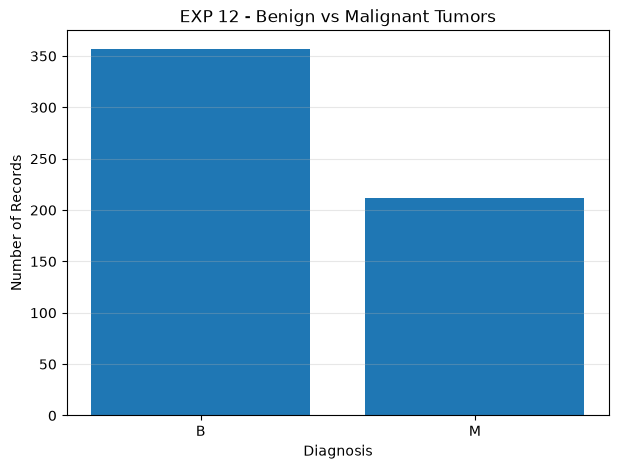

Diagnosis Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [5]:
# EXP 12 - Step 5.1: Diagnosis Distribution

diagnosis_counts = clean_df["diagnosis"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(diagnosis_counts.index, diagnosis_counts.values)

plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.title("EXP 12 - Benign vs Malignant Tumors")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Diagnosis Counts:")
print(diagnosis_counts)

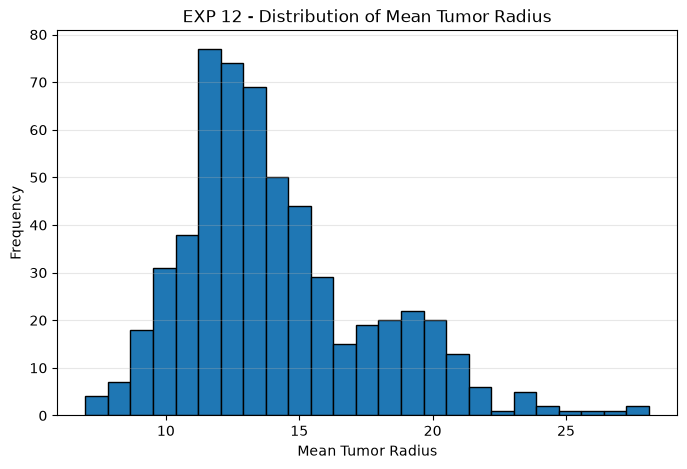

In [6]:
# EXP 12 - Step 5.2: Feature Distribution

plt.figure(figsize=(8, 5))

plt.hist(clean_df["radius_mean"], bins=25, edgecolor="black")

plt.xlabel("Mean Tumor Radius")
plt.ylabel("Frequency")
plt.title("EXP 12 - Distribution of Mean Tumor Radius")
plt.grid(axis="y", alpha=0.3)
plt.show()

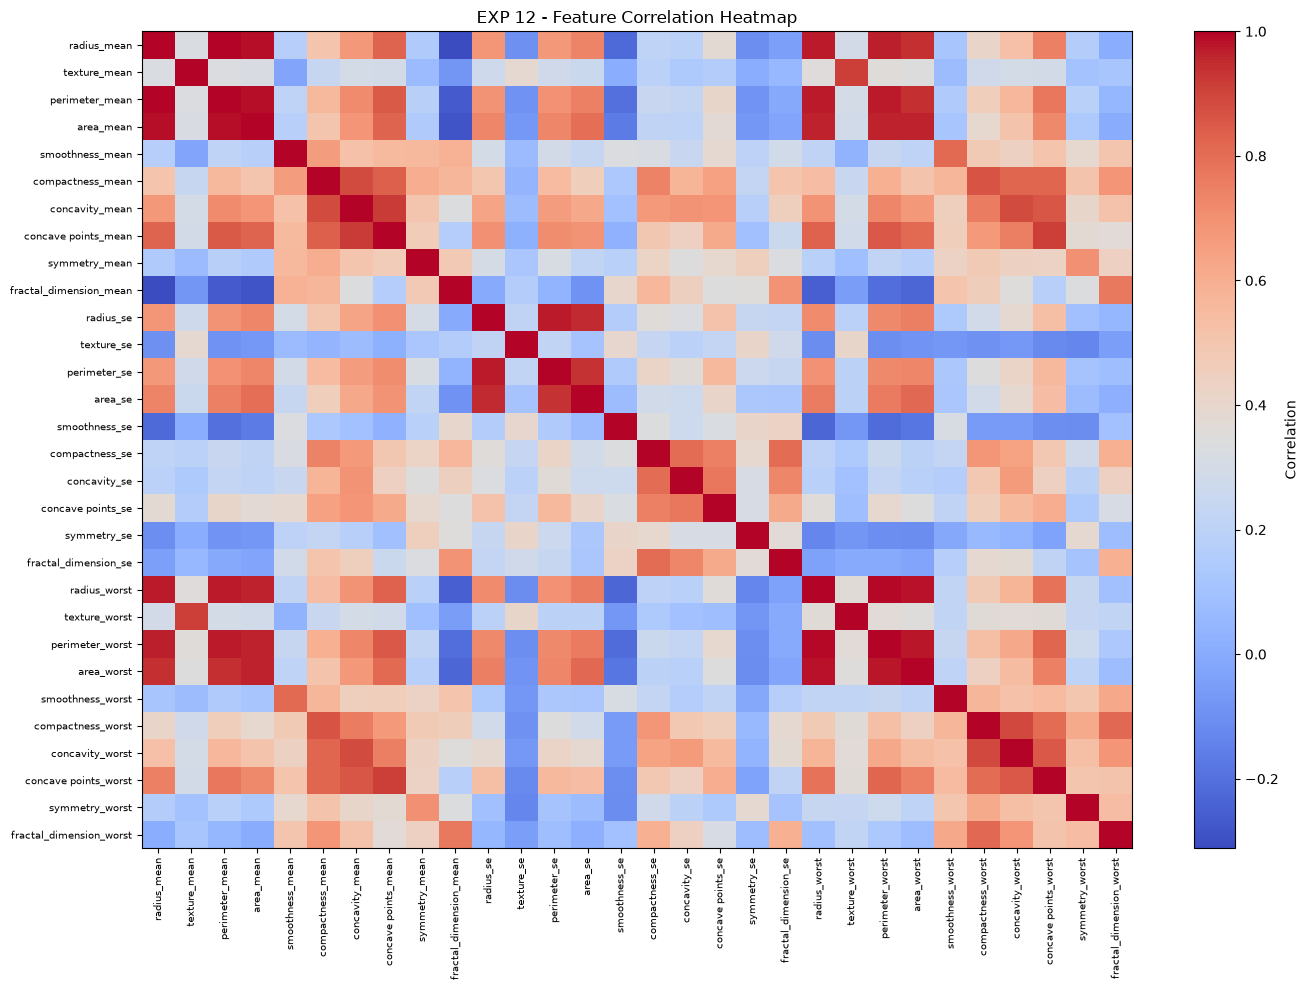

In [7]:
# EXP 12 - Step 5.3: Correlation Heatmap

numeric_df = clean_df.select_dtypes(include=[np.number])

plt.figure(figsize=(14, 10))

correlation = numeric_df.corr()

image = plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar(image, label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns,
    fontsize=7
)

plt.title("EXP 12 - Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [8]:
# EXP 12 - Step 6: Class Imbalance Analysis

class_counts = clean_df["diagnosis"].value_counts()
class_percentages = clean_df["diagnosis"].value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))

imbalance_ratio = class_counts.max() / class_counts.min()

print("\nMajority-to-Minority Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio >= 1.5:
    print("The dataset shows a notable class imbalance.")
else:
    print("The dataset does not show a strong class imbalance.")

print("\nClass imbalance analysis completed.")

Class Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class Percentages:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64

Majority-to-Minority Ratio: 1.68
The dataset shows a notable class imbalance.

Class imbalance analysis completed.


In [9]:
# EXP 12 - Step 7: Dataset Partitioning

from sklearn.model_selection import train_test_split

# Separate input features and target
X = clean_df.drop(columns=["diagnosis"])
y = clean_df["diagnosis"].map({"M": 1, "B": 0})

# Split 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape, y_train.shape)
print("Validation Set:", X_val.shape, y_val.shape)
print("Testing Set:", X_test.shape, y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nValidation Class Distribution:")
print(y_val.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nTesting Class Distribution:")
print(y_test.value_counts().rename(index={0: "Benign", 1: "Malignant"}))

print("\nDataset partitioning completed successfully")

Training Set: (398, 30) (398,)
Validation Set: (85, 30) (85,)
Testing Set: (86, 30) (86,)

Training Class Distribution:
diagnosis
Benign       250
Malignant    148
Name: count, dtype: int64

Validation Class Distribution:
diagnosis
Benign       53
Malignant    32
Name: count, dtype: int64

Testing Class Distribution:
diagnosis
Benign       54
Malignant    32
Name: count, dtype: int64

Dataset partitioning completed successfully


In [10]:
# EXP 12 - Step 8: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training Data Scaled:", X_train_scaled.shape)
print("Validation Data Scaled:", X_val_scaled.shape)
print("Testing Data Scaled:", X_test_scaled.shape)

print("\nFeature scaling completed successfully")

Training Data Scaled: (398, 30)
Validation Data Scaled: (85, 30)
Testing Data Scaled: (86, 30)

Feature scaling completed successfully


In [11]:
# EXP 12 - Step 9: Model Building and Evaluation

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define classification models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Support Vector Machine": make_pipeline(
        StandardScaler(),
        SVC()
    ),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ),

    "Gaussian Naive Bayes": GaussianNB()
}

# Train models and evaluate on validation data
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

# Display comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("Model Comparison on Validation Data")
display(results_df.round(4))

# Identify the best model using validation accuracy
best_model_name = results_df.iloc[0]["Model"]
print("Best Model on Validation Data:", best_model_name)
print(
    "Validation Accuracy:",
    round(results_df.iloc[0]["Accuracy"] * 100, 2), "%"
)

Model Comparison on Validation Data


,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.9765,1.0000,0.9375,0.9677
1,K-Nearest Neighbors,0.9647,1.0000,0.9062,0.9508
2,Logistic Regression,0.9647,1.0000,0.9062,0.9508
3,Random Forest,0.9647,1.0000,0.9062,0.9508
4,Support Vector Machine,0.9529,1.0000,0.8750,0.9333
5,Gaussian Naive Bayes,0.9294,0.9643,0.8438,0.9000
6,Decision Tree,0.8941,0.8966,0.8125,0.8525


Best Model on Validation Data: AdaBoost
Validation Accuracy: 97.65 %


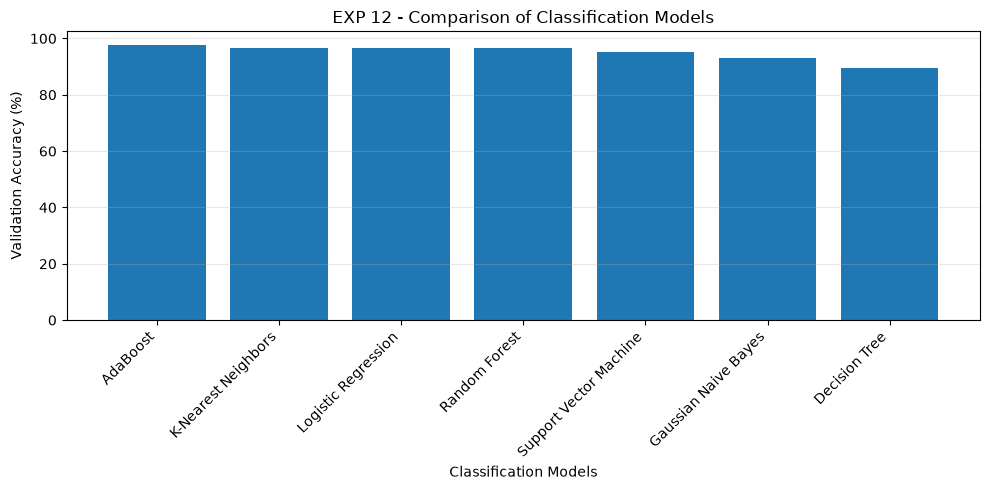

In [12]:
# EXP 12 - Step 10: Model Accuracy Comparison

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"] * 100
)

plt.xlabel("Classification Models")
plt.ylabel("Validation Accuracy (%)")
plt.title("EXP 12 - Comparison of Classification Models")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Selected Model: AdaBoost

Final Test Results
------------------
Accuracy: 98.84 %
Precision: 1.0
Recall: 0.9688
F1 Score: 0.9841

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86

Confusion Matrix:
[[54  0]
 [ 1 31]]


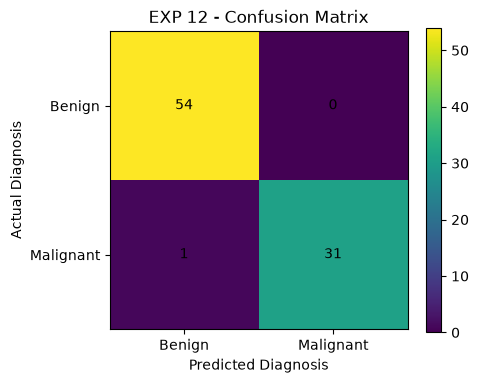

In [13]:
# EXP 12 - Step 11: Final Test Evaluation

best_model = models[best_model_name]

# Predict on unseen test data
y_test_pred = best_model.predict(X_test)

# Calculate metrics
print("Selected Model:", best_model_name)
print("\nFinal Test Results")
print("------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, y_test_pred), 4))

print("Recall:",
      round(recall_score(y_test, y_test_pred), 4))

print("F1 Score:",
      round(f1_score(y_test, y_test_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("EXP 12 - Confusion Matrix")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [14]:
# EXP 12 - Step 12: Final Model Comparison

print("FINAL MODEL COMPARISON")
print("=======================")

display(
    results_df[
        ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
    ].round(4)
)

print("Best Model:", best_model_name)
print("Test Accuracy:",
      round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,AdaBoost,0.9765,1.0000,0.9375,0.9677
1,K-Nearest Neighbors,0.9647,1.0000,0.9062,0.9508
2,Logistic Regression,0.9647,1.0000,0.9062,0.9508
3,Random Forest,0.9647,1.0000,0.9062,0.9508
4,Support Vector Machine,0.9529,1.0000,0.8750,0.9333
5,Gaussian Naive Bayes,0.9294,0.9643,0.8438,0.9000
6,Decision Tree,0.8941,0.8966,0.8125,0.8525


Best Model: AdaBoost
Test Accuracy: 98.84 %
